<a href="https://colab.research.google.com/github/mdeely24/aapl_vs_spy_bayesian/blob/main/aapl_vs_spy_bayesian.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [28]:
!pip install -q pymc arviz yfinance

In [29]:
# Imports and data
import numpy as np
import pandas as pd
import yfinance as yf
import pymc as pm
import arviz as az
import matplotlib.pyplot as plt
from scipy import stats

START, END = "2015-01-01", "2025-12-31"
px = yf.download(["AAPL", "SPY"], start=START, end=END, auto_adjust=True)["Close"]
monthly = px.resample("ME").last().pct_change().dropna()
excess = (monthly["AAPL"] - monthly["SPY"]).rename("excess")
beats = (excess > 0).astype(int)

print(f" {len(excess)} months | AAPL beat SPY in {beats.sum()} ({beats.mean():.1%})")
print(f"Mean monthly excess return: {excess.mean():.4f}  (sd {excess.std():.4f})")

[*********************100%***********************]  2 of 2 completed

 131 months | AAPL beat SPY in 71 (54.2%)
Mean monthly excess return: 0.0093  (sd 0.0594)


# Model 1: Beta-Binomial for P(AAPL beats SPY in a month)
## Prior Beta(2, 2): weakly informative, centered on a coin flip.

   mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  ess_tail  r_hat
p  0.54  0.043   0.464    0.624      0.001      0.0    3227.0    5515.0    1.0


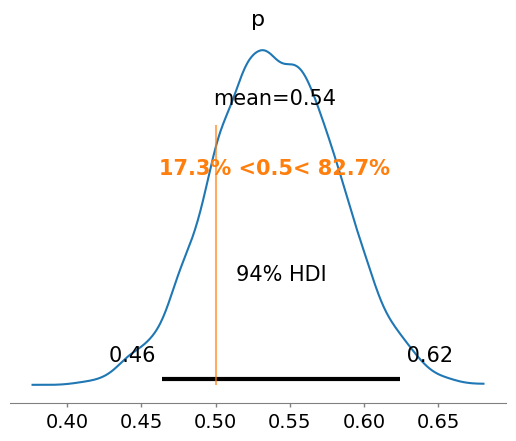

In [30]:
n, wins = len(beats), int(beats.sum())
with pm.Model() as m1:
    p = pm.Beta("p", 2, 2)
    pm.Binomial("wins", n=n, p=p, observed=wins)
    idata1 = pm.sample(2000, tune=1000, chains=4, random_seed=42, progressbar=False)

print(az.summary(idata1, hdi_prob=0.94))
az.plot_posterior(idata1, var_names=["p"], ref_val=0.5)
plt.show()

In [31]:
# Sanity check: conjugate answer is Beta(2 + wins, 2 + losses)
post = stats.beta(2 + wins, 2 + n - wins)
print(f"Analytic posterior mean: {post.mean():.3f}, P(p > 0.5) = {1 - post.cdf(0.5):.3f}")

Analytic posterior mean: 0.541, P(p > 0.5) = 0.829


## Model 2: Student-t model for monthly excess return
Student-t handles fat tails. Priors (in decimal monthly returns):
- mu ~ Normal(0, 0.02): a 2% monthly alpha would be extreme, so this is skeptical but open
- sigma ~ HalfNormal(0.05)
- nu ~ Exponential(1/30): mass on moderately heavy tails

         mean      sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  \
mu      0.009   0.005  -0.001    0.018      0.000    0.000    6337.0   
sigma   0.056   0.004   0.048    0.064      0.000    0.000    4549.0   
nu     31.200  26.822   3.260   81.605      0.409    0.526    3999.0   

       ess_tail  r_hat  
mu       4455.0    1.0  
sigma    3743.0    1.0  
nu       5121.0    1.0  
P(mu > 0 | data) = 0.964
Posterior mean mu = 0.0091 per month (~10.9% per year)


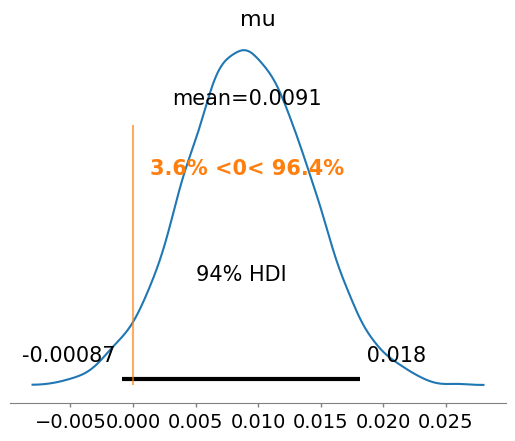

In [32]:
def fit_t(mu_sd=0.02, draws=2000):
    with pm.Model() as m:
        mu = pm.Normal("mu", 0, mu_sd)
        sigma = pm.HalfNormal("sigma", 0.05)
        nu = pm.Exponential("nu", 1 / 30)
        pm.StudentT("r", nu=nu, mu=mu, sigma=sigma, observed=excess.values)
        idata = pm.sample(draws, tune=1000, chains=4, target_accept=0.95,
                          random_seed=42, progressbar=False)
    return m, idata

m2, idata2 = fit_t(0.02)
print(az.summary(idata2, var_names=["mu", "sigma", "nu"], hdi_prob=0.94))
mu_post = idata2.posterior["mu"].values.ravel()
print(f"P(mu > 0 | data) = {(mu_post > 0).mean():.3f}")
print(f"Posterior mean mu = {mu_post.mean():.4f} per month (~{mu_post.mean()*12:.1%} per year)")
az.plot_posterior(idata2, var_names=["mu"], ref_val=0)
plt.show()

## Checks: prior predictive, posterior predictive, sensitivity, frequentist comparison

In [33]:
# Prior predictive: do the priors imply plausible monthly returns?
with m2:
    prior = pm.sample_prior_predictive(500, random_seed=42)
pp = prior.prior_predictive["r"].values.ravel()
print("Prior predictive 1st/99th percentile:", np.percentile(pp, [1, 99]).round(3))

Prior predictive 1st/99th percentile: [-0.2    0.198]


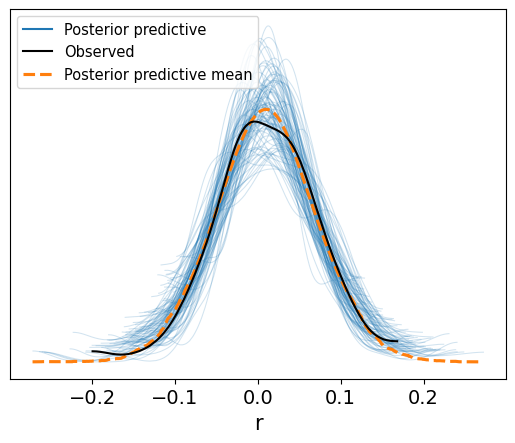

In [34]:
# Posterior predictive check
with m2:
    idata2.extend(pm.sample_posterior_predictive(idata2, random_seed=42, progressbar=False))
az.plot_ppc(idata2, num_pp_samples=100)
plt.show()

In [35]:
# Prior sensitivity on mu
rows = []
for sd in [0.005, 0.02, 0.10]:
    _, idt = fit_t(sd, draws=1000)
    m = idt.posterior["mu"].values.ravel()
    rows.append({"prior_sd": sd, "mean_mu": m.mean(), "P(mu>0)": (m > 0).mean()})
print(pd.DataFrame(rows).round(4))

   prior_sd  mean_mu  P(mu>0)
0     0.005   0.0047   0.9048
1     0.020   0.0092   0.9662
2     0.100   0.0095   0.9665


In [36]:
# Frequentist comparison
t = stats.ttest_1samp(excess, 0)
print(f"One-sample t-test: t={t.statistic:.2f}, p={t.pvalue:.3f}")


One-sample t-test: t=1.79, p=0.076
